# PAS E51 | LGB 3-Seed Rank Refinement

**Purpose:** independently rebuild the E49 rank-space anchor, reproduce the user-validated E50 LightGBM 3-seed 0.25% correction, and run a controlled follow-up search around that direction.

**Current reference:** E49 displayed Public LB 0.96225. The user confirmed that the E50 LGB 3-seed mean 0.25% candidate is higher under Kaggle's best-submission selection, although both rows display 0.96225 at five decimal places. This notebook treats E50 LGB 0.25% as the current user-confirmed best recipe.

**Hard constraints:** no user-owned E49/E50 Notebook Inputs; no OOF; no model fitting/refitting; no test labels; no reading `original_aligned.csv`; no automatic submission; no overwrite of earlier experiment outputs.

**Attribution:** E51 builds on public Kaggle predictions, methods, datasets, and pretrained models by Areeb, tkms0816, Mayankraaz, and Dariush Afshar. Full credits, links, and project-specific contributions appear immediately below this overview.

## Credits & acknowledgements

This experiment builds on public Kaggle work and datasets. We acknowledge the original authors and distinguish their contributions from the E50/E51 experiments performed in this project.

| Source / contributor | Contribution used in this experiment | Reference |
|---|---|---|
| **Areeb** | Published E49 Endgame rank-space recipe and the reported 0.96225 result; E51 independently rebuilds the rank formula from the public prediction assets. | [S6E10 — LESS IS MORE — LB 0.96225](https://www.kaggle.com/code/areebbb/s6e10-endgame-lb-0-96225-rank-22) |
| **tkms0816** | Public `S6E10 push singles` dataset containing `ref_t3_096223.csv`, used as the E49 X anchor. | [S6E10 push singles](https://www.kaggle.com/datasets/tkms0816/s6e10-push-singles) |
| **Mayankraaz** | Public Mirror Nudge Climb III and Mirror Pair Climb prediction outputs used to construct the E49 direction. | [Mirror Nudge Climb III](https://www.kaggle.com/code/mayankraaz/s6e10-mirror-nudge-climb-iii-0-96219) · [Mirror Pair Climb](https://www.kaggle.com/code/mayankraaz/s6e10-mirror-pair-climb-0-96218) |
| **Dariush Afshar** | `S6E10 Original Data + Lookup Tables + Model` dataset, including `original_model.py`, the source feature encoder, and the three saved LightGBM boosters reused for inference. | [Dariush Afshar's S6E10 source notebook](https://www.kaggle.com/code/dariushafshar/s6e10-the-gap-is-3-8-label-noise-not-features) |
| **Kaggle** | Competition data, submission interface, and ROC-AUC evaluation for Predicting Airline Satisfaction / Playground Series S6E10. | [Competition page](https://www.kaggle.com/competitions/playground-series-s6e10) |

### Project-specific contributions

- The **E50 LightGBM 3-seed mean correction at 0.25%** was generated and submitted by the project participant. Its improvement over the E49 submission was confirmed through Kaggle's best-submission selection behavior; the UI displayed both scores rounded to `0.96225`.
- **E51** independently reconstructs the E49 anchor, reruns inference with the cited public LightGBM boosters, reproduces the project-validated E50 candidate, and evaluates additional seed/weight combinations. The E50/E51 adaptations, regression checks, diagnostics, and candidate-generation workflow are project-specific experimental work; they are not attributed to the upstream authors.

### Reuse and licensing note

The cited notebooks, datasets, model files, and prediction outputs remain the work of their respective authors and are included as public Kaggle Inputs. Please follow each asset's displayed license, Kaggle's competition rules, and any applicable dataset/model terms. This notebook does not claim ownership of upstream models, source code, or predictions. Attribution does not imply endorsement by the cited authors.


## 1. Kaggle Inputs — exact checklist

### Competition
- `Predicting Airline Satisfaction` (`playground-series-s6e10`)

### Dataset Inputs — add both
1. `S6E10 push singles` by tkms0816. Required file: `ref_t3_096223.csv` (E49 X anchor).
2. `S6E10 Original Data + Lookup Tables + Model` by Dariush Afshar. Required files: `original_model.py`, `column_mapping.csv`, and the three saved LightGBM model files.

### Notebook Inputs — add both public source Notebooks
1. `S6E10 | Mirror Nudge Climb III` by Mayankraaz. Required output: `submission.csv`.
2. `S6E10 | Mirror Pair Climb` by Mayankraaz. Required output: `submission.csv`.

### Do not add
- Your own PAS E49 Notebook.
- Your own PAS E50 Notebook.
- Mirror Nudge Climb II (not used in this experiment).
- Any OOF-only dataset.

E51 rebuilds E49 internally from the public source predictions and runs the saved LightGBM boosters directly. It does not depend on another user-owned Notebook's output mount.

## 2. Experiment design

### A. Rebuild and freeze E49
\[
R_{E49}=R_X+1.75(R_{MNC3}-R_{MPC}),\qquad
R(v)=\frac{\operatorname{rankdata}(v,\text{average})}{N}
\]

The rebuilt E49 CSV must match the SHA-256 recorded by the completed E50 audit. If it does not, execution stops before model inference or candidate generation.

### B. Reproduce the E50 winning direction

The three LightGBM models are loaded from their existing booster files. Their raw scores are averaged, ranked with E50's exact percentile-rank convention, and blended into the E49 anchor at alpha=0.0025 (0.25%). The regenerated candidate must match the E50 candidate SHA-256.

### C. E51 controlled experiments

1. LGB 3-seed raw-score mean: 0.125%, 0.25%, 0.375%, 0.5%, 0.75%, 1.0%.
2. Individual LGB seeds: each at 0.25%.
3. Leave-one-seed-out 2-seed raw-score means: each at 0.25%.
4. Mean of per-seed percentile ranks: 0.25% and 0.5%.

All candidates are diagnostics until individually evaluated on Kaggle Public LB. Correlation, rank displacement, and tie reduction are not substitutes for AUC.

In [1]:
from pathlib import Path
from collections import Counter
import hashlib
import importlib.util
import json
import sys
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr
from IPython.display import display, FileLink

warnings.filterwarnings('ignore')

INPUT_ROOT = Path('/kaggle/input')
WORK_ROOT = Path('/kaggle/working')
OUT_DIR = WORK_ROOT / 'PAS_E51_LGB_3Seed_Rank_Refinement'
OUT_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_N = 299_844
E49_K = 1.75
E49_FORMULA = 'rank(X) + 1.75 * (rank(MNC3) - rank(MPC))'
E49_EXPECTED_SHA256 = '4f9d59f3371ea093f293f97811679132c8e7edb8b768131151b7019930dc0f4c'
E50_LGB025_EXPECTED_SHA256 = '89091c48d9835404fc679bc4cc5a3ee9d4879add6596a73dba6cb8d14cc4ac58'
E49_REPORTED_PUBLIC_LB = 0.96225
E50_LGB025_DISPLAYED_PUBLIC_LB = 0.96225

EXPECTED_MODEL_SHA256 = {
    'lgb_seed0': '7467a9bae29c473219c816049f0c9a6b4082686a17abf4520ade5f578f762e21',
    'lgb_seed1': '9d30649781483cf4c02c5fe7c41efd0efe3f1134a07781f023848472eaac8808',
    'lgb_seed2': '3b34e7e386fa7de011a4875513c4e0c5c35b75d3f2f9cad8b499ebdf2aceb36b',
}
EXPECTED_ORIGINAL_MODEL_PY_SHA256 = 'd6e7f8f5b12fcc3e3510f29052e832e0788a881d649b92107e316610a2b33f3f'
EXPECTED_COLUMN_MAPPING_SHA256 = '12c372aa7388e12d7a2f52fd14d1569c9a492d75742d2eb675ae4db69024de7a'

LGB_FILES = {
    'lgb_seed0': 'original_model_lgb_seed0.txt',
    'lgb_seed1': 'original_model_lgb_seed1.txt',
    'lgb_seed2': 'original_model_lgb_seed2.txt',
}

# Optional exact path overrides. Leave as None for strict automatic discovery.
PATH_TEST = None
PATH_X = None
PATH_MNC3 = None
PATH_MPC = None
PATH_ORIGINAL_MODEL_PY = None

# E51 search grid. Alpha is a fraction: 0.0025 = 0.25% = 25 basis points.
LGB_MEAN_WEIGHT_GRID = [0.00125, 0.0025, 0.00375, 0.005, 0.0075, 0.01]
INDIVIDUAL_SEED_ALPHA = 0.0025
TWO_SEED_ALPHA = 0.0025
RANK_MEAN_WEIGHT_GRID = [0.0025, 0.005]

print('PAS E51 configuration loaded')
print('E49 anchor formula:', E49_FORMULA)
print('User-confirmed current best recipe: E50 LGB 3-seed mean, alpha=0.25%')
print('OOF / fitting / test labels / auto-submit: DISABLED')

PAS E51 configuration loaded
E49 anchor formula: rank(X) + 1.75 * (rank(MNC3) - rank(MPC))
User-confirmed current best recipe: E50 LGB 3-seed mean, alpha=0.25%
OOF / fitting / test labels / auto-submit: DISABLED


## 3. Shared helpers and strict source discovery

In [2]:
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024 * 1024), b''):
            h.update(block)
    return h.hexdigest()


def unique_or_identical(paths, description, required=True):
    hits = sorted(set(Path(p) for p in paths if Path(p).is_file()))
    if not hits:
        if required:
            raise FileNotFoundError(f'Missing {description}. Check Kaggle Add Input.')
        return None
    hashes = {sha256_file(p) for p in hits}
    if len(hashes) > 1:
        details = '\n'.join(f'{p} | {sha256_file(p)}' for p in hits)
        raise RuntimeError(f'Ambiguous {description}; different files found:\n{details}')
    return hits[0]


def discover_one(pattern, description, predicate=None, override=None, required=True):
    if override is not None:
        p = Path(override)
        if not p.is_file():
            raise FileNotFoundError(f'{description} override does not exist: {p}')
        return p
    hits = list(INPUT_ROOT.rglob(pattern))
    if predicate is not None:
        hits = [p for p in hits if predicate(p)]
    return unique_or_identical(hits, description, required=required)


def load_prediction_csv(path, official_ids, label):
    df = pd.read_csv(path, dtype={'id': 'string'})
    if 'id' not in df.columns:
        raise ValueError(f'{label}: missing id column.')
    if df['id'].isna().any() or df['id'].duplicated().any():
        raise ValueError(f'{label}: missing or duplicate IDs.')
    pred_cols = [c for c in df.columns if c != 'id']
    if len(pred_cols) != 1:
        raise ValueError(f'{label}: expected exactly one prediction column, got {pred_cols}.')
    col = pred_cols[0]
    df[col] = pd.to_numeric(df[col], errors='coerce')
    aligned = df.set_index('id').reindex(pd.Index(official_ids, name='id'))
    values = aligned[col].to_numpy(dtype=np.float64)
    if len(values) != len(official_ids) or not np.isfinite(values).all():
        raise ValueError(f'{label}: ID alignment or finite-value validation failed.')
    return values, col


def source_rank(values):
    values = np.asarray(values, dtype=np.float64).reshape(-1)
    if len(values) != EXPECTED_N or not np.isfinite(values).all():
        raise ValueError('Invalid vector passed to E49 source_rank.')
    return rankdata(values, method='average') / EXPECTED_N


def rank_pct(values):
    values = np.asarray(values, dtype=np.float64).reshape(-1)
    if len(values) != EXPECTED_N or not np.isfinite(values).all():
        raise ValueError('Invalid vector passed to E50 rank_pct.')
    return (rankdata(values, method='average') - 0.5) / EXPECTED_N


def spearman_corr(a, b):
    return float(spearmanr(np.asarray(a), np.asarray(b)).statistic)


def tail_overlap(a, b, fraction=0.001):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    n = len(a)
    k = max(1, int(n * fraction))
    a_top = np.argpartition(a, n-k)[n-k:]
    b_top = np.argpartition(b, n-k)[n-k:]
    a_bottom = np.argpartition(a, k-1)[:k]
    b_bottom = np.argpartition(b, k-1)[:k]
    return (float(len(np.intersect1d(a_top, b_top)) / k),
            float(len(np.intersect1d(a_bottom, b_bottom)) / k))


def tie_stats(values):
    s = pd.Series(np.asarray(values))
    counts = s.value_counts()
    tied = counts[counts > 1]
    return {
        'n_rows': int(len(s)),
        'n_unique': int(s.nunique(dropna=False)),
        'n_tied_rows': int(tied.sum()),
        'n_extra_tied_rows': int((tied - 1).sum()),
        'n_tie_pairs': int(sum(int(v) * (int(v) - 1) // 2 for v in tied)),
    }


def write_float_csv(frame, path):
    frame.to_csv(path, index=False, float_format='%.17g')
    return path


def read_roundtrip(path):
    return pd.read_csv(path, dtype={'id': 'string'}, float_precision='round_trip')


def validate_submission(path, expected_ids, expected_values, label):
    check = read_roundtrip(path)
    if check.columns.tolist() != ['id', 'satisfaction']:
        raise ValueError(f'{label}: unexpected columns {check.columns.tolist()}')
    if len(check) != len(expected_ids):
        raise ValueError(f'{label}: wrong row count.')
    if not np.array_equal(check['id'].to_numpy(), np.asarray(expected_ids, dtype=str)):
        raise ValueError(f'{label}: ID order mismatch.')
    got = check['satisfaction'].to_numpy(dtype=np.float64)
    if not np.isfinite(got).all():
        raise ValueError(f'{label}: non-finite prediction.')
    if not np.array_equal(got, np.asarray(expected_values, dtype=np.float64)):
        raise ValueError(f'{label}: float64 round-trip mismatch.')
    return got

print('Shared helpers ready.')

Shared helpers ready.


## 4. Locate the official test and E49 public prediction sources

In [3]:
print('[1/8] Locating competition and prediction assets...')
TEST_PATH = discover_one(
    'test.csv', 'official competition test.csv',
    predicate=lambda p: p.parent.name == 'playground-series-s6e10' and (p.parent / 'train.csv').is_file(),
    override=PATH_TEST,
)

X_PATH = discover_one(
    'ref_t3_096223.csv', 'tkms0816 X anchor ref_t3_096223.csv',
    predicate=lambda p: 's6e10-push-singles' in str(p).lower() or 'push-singles' in str(p).lower(),
    override=PATH_X,
)

MNC3_PATH = discover_one(
    'submission.csv', 'Mirror Nudge Climb III submission.csv',
    predicate=lambda p: 'mirror-nudge-climb-iii' in str(p).lower(),
    override=PATH_MNC3,
)
MPC_PATH = discover_one(
    'submission.csv', 'Mirror Pair Climb submission.csv',
    predicate=lambda p: 'mirror-pair-climb' in str(p).lower(),
    override=PATH_MPC,
)

print('Official test:', TEST_PATH)
print('X anchor:', X_PATH)
print('MNC3:', MNC3_PATH)
print('MPC:', MPC_PATH)

[1/8] Locating competition and prediction assets...
Official test: /kaggle/input/competitions/playground-series-s6e10/test.csv
X anchor: /kaggle/input/datasets/tkms0816/s6e10-push-singles/ref_t3_096223.csv
MNC3: /kaggle/input/notebooks/mayankraaz/s6e10-mirror-nudge-climb-iii-0-96219/submission.csv
MPC: /kaggle/input/notebooks/mayankraaz/s6e10-mirror-pair-climb-0-96218/submission.csv


## 5. Rebuild E49 internally and freeze the exact anchor

In [4]:
test_df = pd.read_csv(TEST_PATH, dtype={'id': 'string'}, low_memory=False)
if len(test_df) != EXPECTED_N or test_df['id'].isna().any() or test_df['id'].duplicated().any():
    raise ValueError(f'Unexpected official test IDs or row count: {test_df.shape}')
IDS = test_df['id'].astype('string').to_numpy()
IDS_ORIGINAL = test_df['id'].to_numpy()

X, X_COL = load_prediction_csv(X_PATH, IDS, 'X anchor')
MNC3, MNC3_COL = load_prediction_csv(MNC3_PATH, IDS, 'MNC3')
MPC, MPC_COL = load_prediction_csv(MPC_PATH, IDS, 'MPC')

RX = source_rank(X)
RMNC3 = source_rank(MNC3)
RMPC = source_rank(MPC)
E49_SCORE = RX + E49_K * (RMNC3 - RMPC)
if not np.isfinite(E49_SCORE).all():
    raise ValueError('E49 reconstruction produced non-finite scores.')

E49_REBUILT_PATH = OUT_DIR / 'E51_E49_REBUILT_ANCHOR.csv'
write_float_csv(pd.DataFrame({'id': IDS, 'satisfaction': E49_SCORE}), E49_REBUILT_PATH)
validate_submission(E49_REBUILT_PATH, IDS, E49_SCORE, 'E49 rebuilt anchor')
E49_REBUILT_SHA256 = sha256_file(E49_REBUILT_PATH)
print('E49 rebuilt SHA256:', E49_REBUILT_SHA256)
if E49_REBUILT_SHA256 != E49_EXPECTED_SHA256:
    raise RuntimeError(
        'E49 anchor reproduction hash mismatch. Stop: do not run E51 candidates. '
        f'Expected {E49_EXPECTED_SHA256}; got {E49_REBUILT_SHA256}. '
        'Check exact Kaggle source versions, row IDs, and float formatting.'
    )

# E50 reads the E49 CSV back before ranking it. Rank order/ties must remain identical.
E49_REBUILT_READ = read_roundtrip(E49_REBUILT_PATH)
E49_SCORE_ROUNDTRIP = E49_REBUILT_READ['satisfaction'].to_numpy(dtype=np.float64)
if not np.array_equal(rankdata(E49_SCORE_ROUNDTRIP, method='average'),
                      rankdata(E49_SCORE, method='average')):
    raise RuntimeError('E49 CSV round-trip changed the rank/tie structure.')
# Match E50's exact baseline read path: pandas default float parser, then rank_pct.
E49_E50_READ = pd.read_csv(E49_REBUILT_PATH, dtype={'id': 'string'})
E49_SCORE_READ = E49_E50_READ['satisfaction'].to_numpy(dtype=np.float64)
R_E49 = rank_pct(E49_SCORE_READ)

source_audit = pd.DataFrame([
    {'source': 'official_test', 'path': str(TEST_PATH), 'sha256': sha256_file(TEST_PATH), 'rows': len(IDS)},
    {'source': 'X_anchor', 'path': str(X_PATH), 'sha256': sha256_file(X_PATH), 'rows': len(X)},
    {'source': 'MNC3', 'path': str(MNC3_PATH), 'sha256': sha256_file(MNC3_PATH), 'rows': len(MNC3)},
    {'source': 'MPC', 'path': str(MPC_PATH), 'sha256': sha256_file(MPC_PATH), 'rows': len(MPC)},
    {'source': 'E49_rebuilt_anchor', 'path': str(E49_REBUILT_PATH), 'sha256': E49_REBUILT_SHA256, 'rows': len(E49_SCORE)},
])
source_audit.to_csv(OUT_DIR / 'E51_SOURCE_AUDIT.csv', index=False)

E49_REBUILD_AUDIT = {
    'experiment': 'PAS_E51_LGB_3Seed_Rank_Refinement',
    'formula': E49_FORMULA,
    'rank_convention': 'rankdata(method=average) / N',
    'n_test': int(len(IDS)),
    'expected_e49_sha256': E49_EXPECTED_SHA256,
    'rebuilt_e49_sha256': E49_REBUILT_SHA256,
    'e49_hash_match': True,
    'source_paths': {'X': str(X_PATH), 'MNC3': str(MNC3_PATH), 'MPC': str(MPC_PATH)},
    'source_columns': {'X': X_COL, 'MNC3': MNC3_COL, 'MPC': MPC_COL},
    'oof_read': False,
    'training_performed': False,
    'test_labels_read': False,
}
(OUT_DIR / 'E51_E49_REBUILD_AUDIT.json').write_text(
    json.dumps(E49_REBUILD_AUDIT, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('[PASS] E49 anchor rebuilt and hash-verified.')
print('E49 tie statistics:', tie_stats(E49_SCORE))

E49 rebuilt SHA256: 4f9d59f3371ea093f293f97811679132c8e7edb8b768131151b7019930dc0f4c
[PASS] E49 anchor rebuilt and hash-verified.
E49 tie statistics: {'n_rows': 299844, 'n_unique': 287385, 'n_tied_rows': 24491, 'n_extra_tied_rows': 12459, 'n_tie_pairs': 12902}


## 6. Load the original LightGBM models safely

Only the three saved LightGBM boosters are required for E51. The XGBoost model is not loaded because this experiment isolates the LightGBM 3-seed direction. The upstream `score()` and `load()` functions are never called; `load()` may fall back to fitting.

In [5]:
print('[2/8] Locating and verifying original model assets...')
if PATH_ORIGINAL_MODEL_PY is not None:
    ORIGINAL_SCRIPT = Path(PATH_ORIGINAL_MODEL_PY)
    if not ORIGINAL_SCRIPT.is_file():
        raise FileNotFoundError(ORIGINAL_SCRIPT)
else:
    ORIGINAL_SCRIPT = discover_one('original_model.py', 'original_model.py')
ORIG_ROOT = ORIGINAL_SCRIPT.parent
MAPPING_PATH = ORIG_ROOT / 'column_mapping.csv'
if not MAPPING_PATH.is_file():
    raise FileNotFoundError(f'Missing column_mapping.csv beside {ORIGINAL_SCRIPT}')

MODEL_PATHS = {name: ORIG_ROOT / filename for name, filename in LGB_FILES.items()}
for name, path in MODEL_PATHS.items():
    if not path.is_file():
        raise FileNotFoundError(f'Missing {name}: {path}')

original_script_sha = sha256_file(ORIGINAL_SCRIPT)
mapping_sha = sha256_file(MAPPING_PATH)
if original_script_sha != EXPECTED_ORIGINAL_MODEL_PY_SHA256:
    raise RuntimeError(f'original_model.py SHA256 mismatch: {original_script_sha}')
if mapping_sha != EXPECTED_COLUMN_MAPPING_SHA256:
    raise RuntimeError(f'column_mapping.csv SHA256 mismatch: {mapping_sha}')

model_hash_rows = []
for name, path in MODEL_PATHS.items():
    actual = sha256_file(path)
    expected = EXPECTED_MODEL_SHA256[name]
    ok = actual == expected
    model_hash_rows.append({
        'model': name, 'path': str(path), 'sha256': actual,
        'expected_sha256': expected, 'hash_match': bool(ok),
    })
    if not ok:
        raise RuntimeError(f'{name} model SHA256 mismatch: expected {expected}, got {actual}')

model_hash_df = pd.DataFrame(model_hash_rows)
model_hash_df.to_csv(OUT_DIR / 'E51_MODEL_HASH_AUDIT.csv', index=False)
print('[PASS] original_model.py, column mapping, and all three LGB model hashes verified.')

[2/8] Locating and verifying original model assets...
[PASS] original_model.py, column mapping, and all three LGB model hashes verified.


## 7. Apply the exact source encoder and run inference only

In [6]:
spec = importlib.util.spec_from_file_location('pas_e51_original_model_source', ORIGINAL_SCRIPT)
if spec is None or spec.loader is None:
    raise ImportError('Cannot safely import original_model.py.')
original_model = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = original_model
spec.loader.exec_module(original_model)

RAW = list(original_model.RAW)
NUMS = list(original_model.NUMS)
RATINGS = list(original_model.RATINGS)
CATS = list(original_model.CATS)
LEVELS = dict(original_model.LEVELS)
if len(RAW) != 21 or len(set(RAW)) != 21:
    raise ValueError(f'Unexpected original feature list: {RAW}')
if any(c in RAW for c in ['id', 'satisfaction', 'is_original']):
    raise ValueError('ID/target/auxiliary column found in original feature list.')
missing_features = [c for c in RAW if c not in test_df.columns]
if missing_features:
    raise KeyError(f'Official test missing source model features: {missing_features}')

mapping_df = pd.read_csv(MAPPING_PATH, dtype=str).fillna('')
map_rows = mapping_df[mapping_df['source_column'].isin(RAW)].copy()
if set(map_rows['source_column']) != set(RAW):
    raise ValueError('column_mapping.csv does not cover all 21 source features.')
if (map_rows['change'] != 'unchanged').any():
    raise ValueError('Feature mapping reports changed source columns; stop for review.')
if (map_rows['source_column'] != map_rows['column_here']).any():
    raise ValueError('Feature mapping source/competition column names differ.')

X_ENCODED = original_model.encode(test_df)
if list(X_ENCODED.columns) != RAW or X_ENCODED.shape != (EXPECTED_N, 21):
    raise ValueError('Exact upstream encode() output shape/order mismatch.')
X_NUMPY = X_ENCODED.to_numpy(dtype=np.float64)
if np.isinf(X_NUMPY).any():
    raise ValueError('Encoded matrix contains +/- infinity.')

category_rows = []
for col in CATS:
    observed = test_df[col].dropna().astype(str)
    allowed = LEVELS[col]
    unknown = sorted(set(observed.unique()) - set(allowed))
    if unknown:
        raise ValueError(f'Unknown category values in {col}: {unknown}')
    counts = test_df[col].value_counts(dropna=False)
    for level in allowed:
        category_rows.append({
            'feature': col, 'category': level,
            'count': int(counts.get(level, 0)),
            'source_code': int(allowed.index(level)),
        })
    category_rows.append({
        'feature': col, 'category': '__MISSING__',
        'count': int(test_df[col].isna().sum()), 'source_code': np.nan,
    })

feature_rows = []
for i, col in enumerate(RAW):
    feature_rows.append({
        'position_0based': i, 'feature': col,
        'feature_group': 'numeric' if col in NUMS else ('rating' if col in RATINGS else 'categorical'),
        'dtype': str(X_ENCODED[col].dtype),
        'missing_count': int(X_ENCODED[col].isna().sum()),
        'unique_nonmissing': int(X_ENCODED[col].nunique(dropna=True)),
    })
pd.DataFrame(feature_rows).to_csv(OUT_DIR / 'E51_FEATURE_ORDER_AUDIT.csv', index=False)
pd.DataFrame(category_rows).to_csv(OUT_DIR / 'E51_CATEGORY_ENCODING_AUDIT.csv', index=False)

import lightgbm as lgb

expected_lgb_feature_names = [c.replace(' ', '_') for c in RAW]
lgb_boosters = {}
model_status_rows = []
seed_predictions = {}
for name, path in MODEL_PATHS.items():
    booster = lgb.Booster(model_file=str(path))
    feature_names = list(booster.feature_name())
    if int(booster.num_feature()) != 21 or feature_names != expected_lgb_feature_names:
        raise ValueError(f'{name}: model feature count/order mismatch.')
    if int(booster.num_trees()) != 800:
        raise ValueError(f'{name}: expected 800 trees, got {booster.num_trees()}.')
    pred = np.asarray(booster.predict(X_NUMPY, raw_score=True), dtype=np.float64).reshape(-1)
    if len(pred) != EXPECTED_N or not np.isfinite(pred).all():
        raise ValueError(f'{name}: invalid inference output.')
    lgb_boosters[name] = booster
    seed_predictions[name] = pred
    model_status_rows.append({
        'model': name, 'load_status': 'PASS', 'prediction_status': 'PASS',
        'num_features': int(booster.num_feature()),
        'num_trees': int(booster.num_trees()),
        'prediction_min': float(pred.min()),
        'prediction_max': float(pred.max()),
        'prediction_std': float(pred.std()),
    })
    print(name, 'PASS | trees=', booster.num_trees(), '| std=', float(pred.std()))

model_status_df = pd.DataFrame(model_status_rows)
model_status_df.to_csv(OUT_DIR / 'E51_MODEL_INFERENCE_STATUS.csv', index=False)

# Reproduce E50's raw-score arithmetic exactly: equal-weight mean of the three LGB raw scores.
SEED_NAMES = ['lgb_seed0', 'lgb_seed1', 'lgb_seed2']
LGB_MATRIX = np.column_stack([seed_predictions[name] for name in SEED_NAMES])
LGB_RAW_MEAN = LGB_MATRIX.mean(axis=1)
R_LGB_MEAN = rank_pct(LGB_RAW_MEAN)
SEED_RANKS = np.column_stack([rank_pct(seed_predictions[name]) for name in SEED_NAMES])
R_LGB_RANK_MEAN = rank_pct(SEED_RANKS.mean(axis=1))

raw_prediction_df = pd.DataFrame({
    'id': IDS_ORIGINAL,
    'lgb_seed0_raw_score': seed_predictions['lgb_seed0'],
    'lgb_seed1_raw_score': seed_predictions['lgb_seed1'],
    'lgb_seed2_raw_score': seed_predictions['lgb_seed2'],
    'lgb_3seed_raw_mean': LGB_RAW_MEAN,
})
RAW_PRED_PATH = OUT_DIR / 'E51_LGB_3SEED_RAW_TEST_PREDICTIONS.csv'
write_float_csv(raw_prediction_df, RAW_PRED_PATH)

lgb_seed0 PASS | trees= 800 | std= 6.950515303988345
lgb_seed1 PASS | trees= 800 | std= 6.958997654753685
lgb_seed2 PASS | trees= 800 | std= 6.930718807663696


PosixPath('/kaggle/working/PAS_E51_LGB_3Seed_Rank_Refinement/E51_LGB_3SEED_RAW_TEST_PREDICTIONS.csv')

## 8. Seed agreement and dispersion diagnostics

In [7]:
seed_corr_rows = []
for i, left in enumerate(SEED_NAMES):
    for right in SEED_NAMES[i+1:]:
        seed_corr_rows.append({
            'seed_a': left, 'seed_b': right,
            'spearman': spearman_corr(SEED_RANKS[:, SEED_NAMES.index(left)],
                                      SEED_RANKS[:, SEED_NAMES.index(right)]),
        })
seed_corr_df = pd.DataFrame(seed_corr_rows)
seed_corr_df.to_csv(OUT_DIR / 'E51_SEED_CORRELATIONS.csv', index=False)

seed_rank_spread = SEED_RANKS.std(axis=1)
spread_summary = pd.DataFrame([
    {'quantile': q, 'rank_spread': float(np.quantile(seed_rank_spread, q))}
    for q in [0.0, 0.5, 0.9, 0.95, 0.99, 0.999, 1.0]
])
spread_summary.to_csv(OUT_DIR / 'E51_SEED_RANK_SPREAD.csv', index=False)

print('Seed pairwise rank correlations:')
display(seed_corr_df)
print('Across-seed per-row rank spread:')
display(spread_summary)

Seed pairwise rank correlations:


,seed_a,seed_b,spearman
0,lgb_seed0,lgb_seed1,0.995608
1,lgb_seed0,lgb_seed2,0.996325
2,lgb_seed1,lgb_seed2,0.996075


Across-seed per-row rank spread:


,quantile,rank_spread
0,0.000,0.000004
1,0.500,0.008382
2,0.900,0.024560
3,0.950,0.030688
4,0.990,0.043842
5,0.999,0.061679
6,1.000,0.127871


## 9. Generate the E50 exact replay and E51 candidates

The E50 0.25% LGB 3-seed candidate is a hard regression check. Its regenerated CSV must match the recorded E50 SHA-256 before the remaining E51 candidates are accepted.
Candidate filenames are normalized to exactly one `.csv` suffix before writing; the E50 replay hash check reads the same path that was just generated.

On rerun, stale files from the earlier `.csv.csv` bug are removed before candidates are regenerated.


In [8]:
# Remove artifacts from the previous filename bug before regenerating candidates.
stale_candidate_files = sorted(OUT_DIR.glob('E51_*.csv.csv'))
for stale_path in stale_candidate_files:
    stale_path.unlink()
if stale_candidate_files:
    print('Removed stale duplicate-extension candidates:', len(stale_candidate_files))

CANDIDATE_ROWS = []
CANDIDATE_HASHES = {}


def save_candidate(name, source_name, source_rank, alpha, family):
    source_rank = np.asarray(source_rank, dtype=np.float64).reshape(-1)
    if len(source_rank) != EXPECTED_N or not np.isfinite(source_rank).all():
        raise ValueError(f'{name}: invalid source rank vector.')
    raw_blend = R_E49 + float(alpha) * (source_rank - R_E49)
    final_rank = rank_pct(raw_blend)
    filename = str(name)
    if filename.lower().endswith('.csv.csv'):
        raise ValueError(f'{name}: duplicate .csv extension supplied.')
    if not filename.lower().endswith('.csv'):
        filename += '.csv'
    path = OUT_DIR / filename
    frame = pd.DataFrame({'id': IDS_ORIGINAL, 'satisfaction': final_rank})
    write_float_csv(frame, path)
    check = validate_submission(path, IDS, final_rank, name)
    digest = sha256_file(path)
    top001, bottom001 = tail_overlap(R_E49, check, 0.001)
    top01, bottom01 = tail_overlap(R_E49, check, 0.01)
    ties = tie_stats(check)
    CANDIDATE_HASHES[name] = digest
    CANDIDATE_ROWS.append({
        'file': path.name,
        'family': family,
        'source': source_name,
        'alpha': float(alpha),
        'alpha_percent': float(alpha * 100.0),
        'rows': int(len(check)),
        'spearman_vs_e49': spearman_corr(R_E49, check),
        'rank_delta_std': float(np.std(check - R_E49)),
        'rank_delta_abs_p95': float(np.quantile(np.abs(check - R_E49), 0.95)),
        'rank_delta_abs_p99': float(np.quantile(np.abs(check - R_E49), 0.99)),
        'top_0.1pct_overlap': top001,
        'bottom_0.1pct_overlap': bottom001,
        'top_1pct_overlap': top01,
        'bottom_1pct_overlap': bottom01,
        'n_unique_scores': ties['n_unique'],
        'n_tied_rows': ties['n_tied_rows'],
        'n_tie_pairs': ties['n_tie_pairs'],
        'sha256': digest,
        'public_lb': 'NOT_SUBMITTED',
        'submission_recommended': False,
    })
    return path

# Track A: E50 reproduction and a local weight sweep around the winning 0.25% point.
for alpha in LGB_MEAN_WEIGHT_GRID:
    pct = alpha * 100.0
    tag = str(pct).replace('.', 'P')
    save_candidate(
        f'E51_LGB_RAWMEAN_W{tag}.csv',
        'equal-weight mean of three LightGBM raw scores',
        R_LGB_MEAN, alpha, 'lgb_3seed_raw_mean_weight_sweep'
    )

replayed_name = 'E51_LGB_RAWMEAN_W0P25.csv'
replayed_path = OUT_DIR / replayed_name
replayed_sha = sha256_file(replayed_path)
if replayed_sha != E50_LGB025_EXPECTED_SHA256:
    raise RuntimeError(
        'E50 winning candidate replay hash mismatch. Stop before using E51 candidates. '
        f'Expected {E50_LGB025_EXPECTED_SHA256}; got {replayed_sha}.'
    )
print('[PASS] E50 LGB 0.25% candidate reproduced byte-for-byte:', replayed_sha)

# Track B: individual seed directions at the E50 winning alpha.
for seed_name in SEED_NAMES:
    save_candidate(
        f'E51_{seed_name.upper()}_W0P25.csv',
        f'individual {seed_name} raw score',
        rank_pct(seed_predictions[seed_name]), INDIVIDUAL_SEED_ALPHA,
        'individual_seed_direction'
    )

# Track C: leave-one-seed-out two-seed raw-score means.
for omitted in SEED_NAMES:
    kept = [name for name in SEED_NAMES if name != omitted]
    pair_mean = np.mean(np.column_stack([seed_predictions[name] for name in kept]), axis=1)
    save_candidate(
        f'E51_LGB_PAIR_{kept[0].upper()}_{kept[1].upper()}_W0P25.csv',
        f'two-seed raw mean excluding {omitted}',
        rank_pct(pair_mean), TWO_SEED_ALPHA,
        'leave_one_seed_out_pair_mean'
    )

# Track D: average the three seed percentile ranks instead of averaging raw scores.
for alpha in RANK_MEAN_WEIGHT_GRID:
    tag = str(alpha * 100.0).replace('.', 'P')
    save_candidate(
        f'E51_LGB_RANKMEAN_W{tag}.csv',
        'mean of three per-seed percentile ranks',
        R_LGB_RANK_MEAN, alpha,
        'per_seed_rank_mean'
    )

candidate_df = pd.DataFrame(CANDIDATE_ROWS)
candidate_df.to_csv(OUT_DIR / 'E51_CANDIDATE_MANIFEST.csv', index=False)
print('Candidate count:', len(candidate_df))
display(candidate_df[['file', 'family', 'alpha_percent', 'spearman_vs_e49', 'rank_delta_std', 'sha256']])

[PASS] E50 LGB 0.25% candidate reproduced byte-for-byte: 89091c48d9835404fc679bc4cc5a3ee9d4879add6596a73dba6cb8d14cc4ac58
Candidate count: 14


,file,family,alpha_percent,spearman_vs_e49,rank_delta_std,sha256
0,E51_LGB_RAWMEAN_W0P125.csv,lgb_3seed_raw_mean_weight_sweep,0.125,1.000000,0.000145,486e423192d5485ffa4b73e710d7b07a346be08e8e36c1...
1,E51_LGB_RAWMEAN_W0P25.csv,lgb_3seed_raw_mean_weight_sweep,0.250,0.999999,0.000290,89091c48d9835404fc679bc4cc5a3ee9d4879add6596a7...
2,E51_LGB_RAWMEAN_W0P375.csv,lgb_3seed_raw_mean_weight_sweep,0.375,0.999999,0.000435,57765a9bc9a97103772e5aa0d0e4016fae720bb8494f4f...
3,E51_LGB_RAWMEAN_W0P5.csv,lgb_3seed_raw_mean_weight_sweep,0.500,0.999998,0.000580,7d86431f3e84b46a38882427a46488574be13993fd8da0...
4,E51_LGB_RAWMEAN_W0P75.csv,lgb_3seed_raw_mean_weight_sweep,0.750,0.999995,0.000871,b9e89d4dffc98a4d86814b6364e5e45e1aad692497f09e...
5,E51_LGB_RAWMEAN_W1P0.csv,lgb_3seed_raw_mean_weight_sweep,1.000,0.999992,0.001163,fb9e8d03a8470f3d7d7c1875567d380b8484e8bca604d0...
6,E51_LGB_SEED0_W0P25.csv,individual_seed_direction,0.250,0.999999,0.000290,c215a03c759949d63b364a18d3be1588b2431bf75f1ed2...
7,E51_LGB_SEED1_W0P25.csv,individual_seed_direction,0.250,0.999999,0.000290,bfa2f4953c4ffdb5c72e4d7c806a505ce61cc7b7d28dc4...
8,E51_LGB_SEED2_W0P25.csv,individual_seed_direction,0.250,0.999999,0.000290,5bd19327ddb8fcfb353d93519d582449a45ec613493dfc...
9,E51_LGB_PAIR_LGB_SEED1_LGB_SEED2_W0P25.csv,leave_one_seed_out_pair_mean,0.250,0.999999,0.000290,f91c852a8bfe14c39f43c09d2e28128d4eaf2c902aa137...


## 10. Visual diagnostics

These figures describe prediction geometry and perturbation size only. They do not estimate Public LB or AUC.

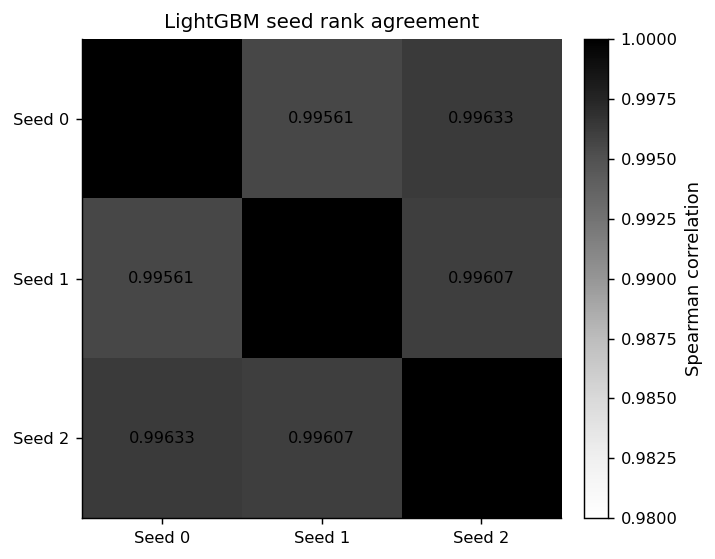

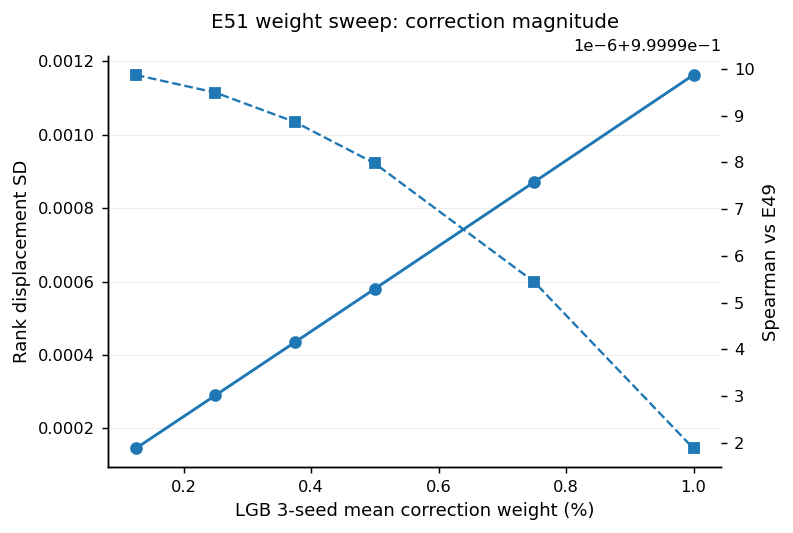

In [9]:
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans'],
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.8,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.dpi': 130,
    'savefig.dpi': 180,
})

corr_matrix = np.corrcoef(SEED_RANKS.T)
fig, ax = plt.subplots(figsize=(5.4, 4.4))
im = ax.imshow(corr_matrix, vmin=0.98, vmax=1.0, cmap='Greys')
ax.set_xticks(range(3), ['Seed 0', 'Seed 1', 'Seed 2'])
ax.set_yticks(range(3), ['Seed 0', 'Seed 1', 'Seed 2'])
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{corr_matrix[i, j]:.5f}', ha='center', va='center', fontsize=9)
ax.set_title('LightGBM seed rank agreement')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label='Spearman correlation')
fig.tight_layout()
fig.savefig(OUT_DIR / 'E51_FIG1_SEED_RANK_CORRELATION.png', bbox_inches='tight')
plt.show()

mean_sweep = candidate_df[candidate_df['family'] == 'lgb_3seed_raw_mean_weight_sweep'].sort_values('alpha')
fig, ax1 = plt.subplots(figsize=(6.2, 4.2))
ax1.plot(mean_sweep['alpha_percent'], mean_sweep['rank_delta_std'], marker='o', linewidth=1.6, label='Rank displacement SD')
ax1.set_xlabel('LGB 3-seed mean correction weight (%)')
ax1.set_ylabel('Rank displacement SD')
ax1.grid(axis='y', alpha=0.22, linewidth=0.6)
ax2 = ax1.twinx()
ax2.plot(mean_sweep['alpha_percent'], mean_sweep['spearman_vs_e49'], marker='s', linestyle='--', linewidth=1.3, label='Spearman vs E49')
ax2.set_ylabel('Spearman vs E49')
ax1.set_title('E51 weight sweep: correction magnitude')
fig.tight_layout()
fig.savefig(OUT_DIR / 'E51_FIG2_WEIGHT_SWEEP_DIAGNOSTICS.png', bbox_inches='tight')
plt.show()

## 11. Final audit, summary, and package

In [10]:
# Preserve explicit provenance in the runtime output package.
CREDITS_TEXT = r"""## Credits & acknowledgements

This experiment builds on public Kaggle work and datasets. We acknowledge the original authors and distinguish their contributions from the E50/E51 experiments performed in this project.

| Source / contributor | Contribution used in this experiment | Reference |
|---|---|---|
| **Areeb** | Published E49 Endgame rank-space recipe and the reported 0.96225 result; E51 independently rebuilds the rank formula from the public prediction assets. | [S6E10 — LESS IS MORE — LB 0.96225](https://www.kaggle.com/code/areebbb/s6e10-endgame-lb-0-96225-rank-22) |
| **tkms0816** | Public `S6E10 push singles` dataset containing `ref_t3_096223.csv`, used as the E49 X anchor. | [S6E10 push singles](https://www.kaggle.com/datasets/tkms0816/s6e10-push-singles) |
| **Mayankraaz** | Public Mirror Nudge Climb III and Mirror Pair Climb prediction outputs used to construct the E49 direction. | [Mirror Nudge Climb III](https://www.kaggle.com/code/mayankraaz/s6e10-mirror-nudge-climb-iii-0-96219) · [Mirror Pair Climb](https://www.kaggle.com/code/mayankraaz/s6e10-mirror-pair-climb-0-96218) |
| **Dariush Afshar** | `S6E10 Original Data + Lookup Tables + Model` dataset, including `original_model.py`, the source feature encoder, and the three saved LightGBM boosters reused for inference. | [Dariush Afshar's S6E10 source notebook](https://www.kaggle.com/code/dariushafshar/s6e10-the-gap-is-3-8-label-noise-not-features) |
| **Kaggle** | Competition data, submission interface, and ROC-AUC evaluation for Predicting Airline Satisfaction / Playground Series S6E10. | [Competition page](https://www.kaggle.com/competitions/playground-series-s6e10) |

### Project-specific contributions

- The **E50 LightGBM 3-seed mean correction at 0.25%** was generated and submitted by the project participant. Its improvement over the E49 submission was confirmed through Kaggle's best-submission selection behavior; the UI displayed both scores rounded to `0.96225`.
- **E51** independently reconstructs the E49 anchor, reruns inference with the cited public LightGBM boosters, reproduces the project-validated E50 candidate, and evaluates additional seed/weight combinations. The E50/E51 adaptations, regression checks, diagnostics, and candidate-generation workflow are project-specific experimental work; they are not attributed to the upstream authors.

### Reuse and licensing note

The cited notebooks, datasets, model files, and prediction outputs remain the work of their respective authors and are included as public Kaggle Inputs. Please follow each asset's displayed license, Kaggle's competition rules, and any applicable dataset/model terms. This notebook does not claim ownership of upstream models, source code, or predictions. Attribution does not imply endorsement by the cited authors.
"""
(OUT_DIR / 'E51_CREDITS_AND_ACKNOWLEDGEMENTS.md').write_text(
    CREDITS_TEXT, encoding='utf-8'
)



2808

In [11]:
# Recheck immutable E49 and winning E50 reproduction artifacts.
assert sha256_file(E49_REBUILT_PATH) == E49_EXPECTED_SHA256
assert sha256_file(replayed_path) == E50_LGB025_EXPECTED_SHA256
assert len(candidate_df) == len(CANDIDATE_ROWS)
assert candidate_df['rows'].eq(EXPECTED_N).all()
assert model_status_df['prediction_status'].eq('PASS').all()

summary = {
    'experiment': 'PAS_E51_LGB_3Seed_Rank_Refinement',
    'source_attribution': {
        'e49_rank_recipe': 'Areeb — S6E10 Endgame LB 0.96225',
        'x_anchor': 'tkms0816 — S6E10 push singles',
        'mnc3_and_mpc_predictions': 'Mayankraaz — Mirror Nudge Climb III and Mirror Pair Climb',
        'lightgbm_models_and_encoder': 'Dariush Afshar — S6E10 Original Data + Lookup Tables + Model',
        'competition': 'Kaggle — Predicting Airline Satisfaction / Playground Series S6E10',
        'e50_025_percent_result': 'Project-participant experiment and Kaggle submission; not an upstream result',
        'e51_extensions': 'Project-specific reproduction, audit, and seed/weight experiments',
    },
    'current_best_user_confirmed': {
        'recipe': 'E50 LGB 3-seed raw-score mean correction at alpha=0.0025',
        'displayed_public_lb': E50_LGB025_DISPLAYED_PUBLIC_LB,
        'user_confirmed_better_than_e49': True,
        'note': 'Kaggle UI displays five decimals; the user confirmed the E50 submission is higher under the platform best-submission selection.'
    },
    'e49_anchor': {
        'formula': E49_FORMULA,
        'expected_sha256': E49_EXPECTED_SHA256,
        'rebuilt_sha256': E49_REBUILT_SHA256,
        'hash_match': True,
        'reported_public_lb': E49_REPORTED_PUBLIC_LB,
    },
    'e50_replay': {
        'candidate': replayed_name,
        'expected_sha256': E50_LGB025_EXPECTED_SHA256,
        'rebuilt_sha256': replayed_sha,
        'hash_match': True,
        'alpha': 0.0025,
    },
    'test_rows': int(EXPECTED_N),
    'feature_count': int(len(RAW)),
    'model_status': model_status_rows,
    'candidate_count': int(len(candidate_df)),
    'candidate_files': candidate_df['file'].tolist(),
    'oof_read': False,
    'training_performed': False,
    'fit_or_refit_called': False,
    'original_aligned_target_read': False,
    'competition_test_labels_read': False,
    'automatic_submission': False,
    'historical_outputs_overwritten': False,
    'caveat': 'All new candidates require separate Kaggle Public LB evaluation. Correlation and rank diagnostics do not establish AUC improvement; repeated Public LB selection can overfit the public split.'
}
(OUT_DIR / 'E51_SUMMARY.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')

readme = """# PAS E51 | LGB 3-Seed Rank Refinement

## Purpose
Independently rebuild the E49 rank-space anchor, reproduce the user-validated E50 LightGBM 3-seed 0.25% correction, and test a controlled set of follow-up LightGBM ranking refinements.

## Kaggle Inputs
- Competition: Predicting Airline Satisfaction (`playground-series-s6e10`).
- Dataset: `S6E10 push singles` by tkms0816 (`ref_t3_096223.csv`).
- Dataset: `S6E10 Original Data + Lookup Tables + Model` by Dariush Afshar (`original_model.py`, `column_mapping.csv`, three LightGBM boosters).
- Notebook: public `S6E10 | Mirror Nudge Climb III` by Mayankraaz (`submission.csv`).
- Notebook: public `S6E10 | Mirror Pair Climb` by Mayankraaz (`submission.csv`).

Do NOT add the user's own E49 or E50 Notebook. Do not add Mirror Nudge Climb II.

## What it does
1. Rebuilds E49 using `rankdata(method='average') / N` and verifies the historical E49 CSV SHA-256.
2. Loads the three existing LightGBM boosters directly; uses the exact upstream `encode()` and never calls fit/refit.
3. Reproduces E50's LGB 3-seed mean 0.25% candidate and verifies its SHA-256.
4. Generates a small E51 sweep, individual-seed, pair-mean, and rank-mean candidates.
5. Exports audit tables, figures, manifest, summary JSON, and a ZIP.

## Safety
- No OOF files read.
- No test labels read.
- No `original_aligned.csv` read.
- No model training, fitting, or refitting.
- No automatic Kaggle submission.
- No previous experiment output is overwritten.

## Important interpretation
Only Kaggle Public LB can establish whether a candidate improves the competition score. Spearman correlation, tail overlap, rank displacement, and tie reduction are diagnostics, not AUC estimates. Public-LB selection can overfit the public split.

## Outputs
`/kaggle/working/PAS_E51_LGB_3Seed_Rank_Refinement/` contains the rebuilt E49 anchor, raw LGB predictions, candidate CSVs, source/model audits, candidate manifest, figures, and summary. The complete folder is packaged as `PAS_E51_LGB_3Seed_Rank_Refinement.zip`.
"""
(OUT_DIR / 'README.md').write_text(readme, encoding='utf-8')

zip_path = WORK_ROOT / 'PAS_E51_LGB_3Seed_Rank_Refinement.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED, compresslevel=5) as zf:
    for p in sorted(OUT_DIR.rglob('*')):
        if p.is_file():
            zf.write(p, arcname=str(p.relative_to(OUT_DIR)))

print('\n' + '=' * 76)
print('PAS E51 PACKAGE COMPLETE')
print('=' * 76)
print('E49 rebuilt hash:', E49_REBUILT_SHA256)
print('E50 LGB 0.25% replay hash:', replayed_sha)
print('Candidates generated:', len(candidate_df))
print('Models passed:', int(model_status_df['prediction_status'].eq('PASS').sum()), '/ 3')
print('OOF / training / test labels / auto-submit: NO')
print('ZIP:', zip_path)
display(FileLink(str(zip_path)))


PAS E51 PACKAGE COMPLETE
E49 rebuilt hash: 4f9d59f3371ea093f293f97811679132c8e7edb8b768131151b7019930dc0f4c
E50 LGB 0.25% replay hash: 89091c48d9835404fc679bc4cc5a3ee9d4879add6596a73dba6cb8d14cc4ac58
Candidates generated: 14
Models passed: 3 / 3
OOF / training / test labels / auto-submit: NO
ZIP: /kaggle/working/PAS_E51_LGB_3Seed_Rank_Refinement.zip


/kaggle/working/PAS_E51_LGB_3Seed_Rank_Refinement.zip

## 12. Submission policy and next action

Do not submit all candidates. First inspect `E51_CANDIDATE_MANIFEST.csv`. Keep the user-confirmed E50 LGB 0.25% submission as the current best. Select only a small number of E51 candidates for Kaggle evaluation, recording the exact displayed score and submission name. Because the UI rounds to five decimals, preserve Kaggle's best-submission selection behavior and do not infer a tie from equal displayed values.